In [1]:
import zipfile
from io import StringIO
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
cwd = Path.cwd()
data_root = cwd.parent / 'data' if (cwd.parent / 'data').exists() else cwd / 'data'
zip_path = data_root / 'lowdim_algorithm_benchmark_data.zip'
DATA = data_root / 'lowdim_algorithm_benchmark_data'

if not DATA.exists():
    if not zip_path.exists():
        raise FileNotFoundError(
            f'Missing benchmark data. Expected either {DATA} or {zip_path}.'
        )
    DATA.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATA)

required_files = [
    'lowdim_exact_oracle_benchmark_data.csv',
    'lowdim_exact_oracle_benchmark_local_search_data.csv',
]
missing = [name for name in required_files if not (DATA / name).exists()]
if missing:
    raise FileNotFoundError(f'Missing benchmark data files in {DATA}: {", ".join(missing)}')

OUT = Path('outputs') / 'lowdim_algorithm_design_heatmap_outputs'
FIG = OUT / 'figures'
OUT_DATA = OUT / 'data'
FIG.mkdir(parents=True, exist_ok=True)
OUT_DATA.mkdir(parents=True, exist_ok=True)

heat_path = DATA / 'lowdim_exact_oracle_benchmark_heatmap.csv'
if not heat_path.exists():
    alt_path = Path('lowdim_exact_oracle_benchmark_heatmap.csv')
    if alt_path.exists():
        heat_path = alt_path
    else:
        raise FileNotFoundError('Run the data-generation notebook first. Missing: ' + str(heat_path))

heat_df = pd.read_csv(heat_path, index_col=0)

heat_df

,Best subset (no reg.),Greedy + local refinement,Weighted rounding only,Weighted screen-and-refit (proposed)
condition,,,,
identity-independent,1.178267,1.0,1.000000,1.0
identity-tradeoff,1.121401,1.0,1.003292,1.0
ar1-independent,1.544874,1.0,1.019020,1.0
ar1-tradeoff,1.323883,1.0,1.000000,1.0
block-independent,1.653910,1.0,1.000000,1.0
block-tradeoff,1.516954,1.0,1.000000,1.0


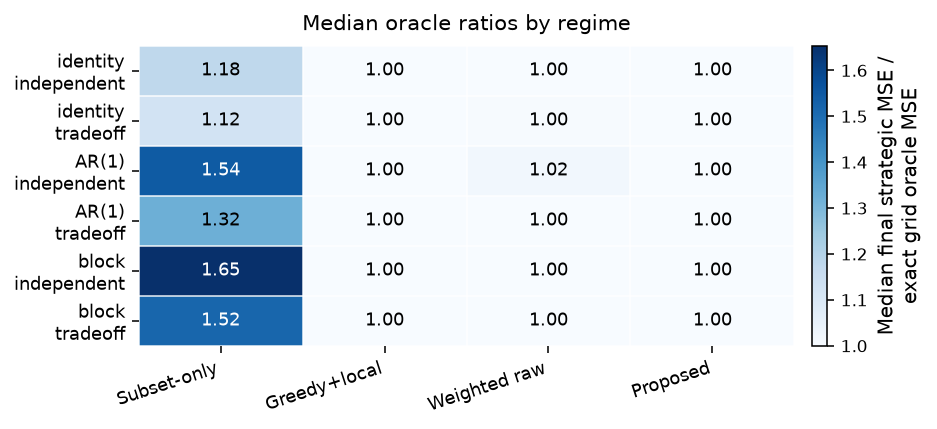

In [3]:
METHODS = [
    'Best subset (no reg.)',
    'Greedy + local refinement',
    'Weighted rounding only',
    'Weighted screen-and-refit (proposed)',
]
METHOD_LABELS = ['Subset-only', 'Greedy+local', 'Weighted raw', 'Proposed']
CONDITION_ORDER = [
    'identity-independent',
    'identity-tradeoff',
    'ar1-independent',
    'ar1-tradeoff',
    'block-independent',
    'block-tradeoff',
]
CONDITION_TITLES = {
    'identity-independent': 'identity, independent',
    'identity-tradeoff': 'identity, tradeoff',
    'ar1-independent': 'AR(1), independent',
    'ar1-tradeoff': 'AR(1), tradeoff',
    'block-independent': 'block, independent',
    'block-tradeoff': 'block, tradeoff',
}

plt.rcParams.update({
    'font.size': 9.5,
    'axes.titlesize': 11.0,
    'axes.labelsize': 10.2,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

heat = heat_df.loc[CONDITION_ORDER, METHODS]
fig, ax = plt.subplots(figsize=(6.9, 3.35))
vmax = max(1.30, float(heat.values.max()))
im = ax.imshow(heat.values, aspect='auto', cmap='Blues', vmin=1.0, vmax=vmax)
ax.set_xticks(range(len(METHODS)))
ax.set_xticklabels(METHOD_LABELS, rotation=18, ha='right')
ax.set_yticks(range(len(CONDITION_ORDER)))
ax.set_yticklabels([CONDITION_TITLES[c].replace(', ', '\n') for c in CONDITION_ORDER])
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        val = float(heat.values[i, j])
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', color='white' if val > 1.35 else 'black', fontsize=9.2)
ax.set_title('Median oracle ratios by regime', loc='center', pad=8)
ax.set_xticks(np.arange(-0.5, len(METHODS), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(CONDITION_ORDER), 1), minor=True)
ax.grid(which='minor', color='white', linewidth=0.9, alpha=0.8)
ax.tick_params(which='minor', bottom=False, left=False)
for spine in ax.spines.values():
    spine.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.025)
cbar.set_label('Median final strategic MSE /\nexact grid oracle MSE')
cbar.ax.tick_params(labelsize=8.5)
fig.subplots_adjust(left=0.19, right=0.92, bottom=0.24, top=0.88)
fig.savefig(FIG / 'lowdim_algorithm_design_heatmap.pdf', bbox_inches='tight')
fig.savefig(FIG / 'lowdim_algorithm_design_heatmap.png', bbox_inches='tight')
plt.show()